[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/12_from_here_to_gpt_and_bert.ipynb)

# 12 · From Here to GPT and BERT

*Attention, Explained · Hamza Hentabli, Ph.D. · ~35 min*

You now know every part of a Transformer. This final notebook connects the toy models of this course to the real ones: the three architecture families (**BERT**, **GPT**, **T5**), their pretraining objectives — demonstrated by training a tiny GPT and a tiny BERT live — how parameter counts scale, why attention's cost grows with the square of the context, and a one-page cheat-sheet of the whole course.

**Learning objectives.** By the end of this notebook you will be able to:

- distinguish **encoder-only**, **decoder-only** and **encoder–decoder** Transformers by their masks
- train a tiny **GPT-style** (next-token) and **BERT-style** (masked-word) model on a toy corpus
- compute the **parameter count** of GPT-2 from its shape
- measure the **quadratic cost** of attention and name the tricks that tame it
- review the whole course on a one-page **cheat-sheet**

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. Three families, one mechanism

Every famous Transformer is built from the block of Notebook 09. What differs is **who may attend to whom** (the mask) and **what the model is trained to predict**.

| family | attention pattern | pretraining objective | examples | good at |
|--------|-------------------|-----------------------|----------|---------|
| **Encoder-only** | bidirectional: every token sees every token | **masked language modelling** (fill in hidden words) | BERT, RoBERTa, (ChemBERTa, ESM for proteins) | understanding: classification, tagging, embeddings |
| **Decoder-only** | **causal**: token $i$ sees $\le i$ (Notebook 10) | **next-token prediction** | GPT family, LLaMA, most chat LLMs | generation |
| **Encoder–decoder** | encoder bidirectional; decoder causal **plus cross-attention** to the encoder | sequence-to-sequence (e.g. denoising, translation) | original Transformer, T5, BART | translation, summarisation |

The cross-attention in the third row is exactly the attention of Notebook 01: decoder queries, encoder keys and values. Below, the three patterns drawn as masks.

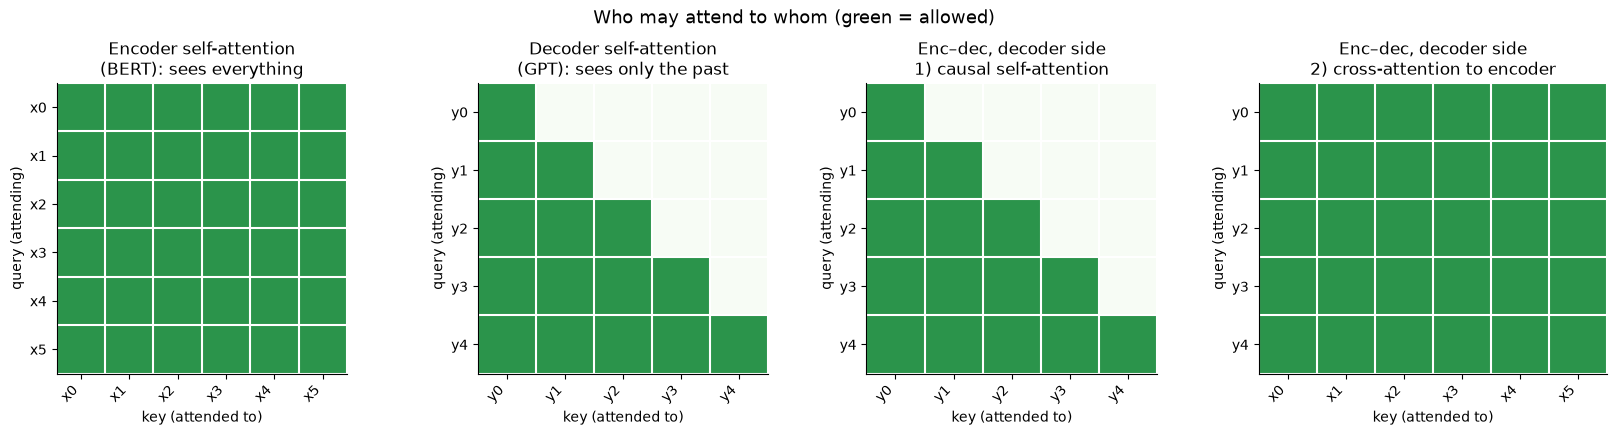

In [2]:
n_src, n_tgt = 6, 5
bidir = np.ones((n_src, n_src))
causal = (~au.causal_mask(n_tgt)).astype(float)
cross = np.ones((n_tgt, n_src))

fig, axes = plt.subplots(1, 4, figsize=(17, 4.3), gridspec_kw={"width_ratios": [6, 5, 5, 6]})
src = [f"x{i}" for i in range(n_src)]; tgt = [f"y{i}" for i in range(n_tgt)]
for ax, M, rows, cols, title in [
    (axes[0], bidir, src, src, "Encoder self-attention\n(BERT): sees everything"),
    (axes[1], causal, tgt, tgt, "Decoder self-attention\n(GPT): sees only the past"),
    (axes[2], causal, tgt, tgt, "Enc–dec, decoder side\n1) causal self-attention"),
    (axes[3], cross, tgt, src, "Enc–dec, decoder side\n2) cross-attention to encoder"),
]:
    au.plot_attention(M, rows, cols, ax=ax, annotate=False, cmap="Greens", vmax=1.4, title=title)
    for k in range(M.shape[0] + 1): ax.axhline(k - 0.5, color="white", lw=1.5)
    for k in range(M.shape[1] + 1): ax.axvline(k - 0.5, color="white", lw=1.5)
fig.suptitle("Who may attend to whom (green = allowed)", fontsize=13)
plt.tight_layout()
au.save_fig(fig, "12_architectures_masks.png")
plt.show()

## 2. The two pretraining objectives, for real

Pretraining needs **no labels**: the text supervises itself. We demonstrate both objectives on our 45-sentence toy corpus with tiny models. (Real models do the same thing on trillions of tokens.)

### 2a. GPT-style: next-character prediction

A tiny **decoder-only** Transformer at the character level, trained to predict the next character with a causal mask, then asked to write.

In [3]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.set_num_threads(4)

text = " . ".join(au.TOY_CORPUS) + " ."
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text])
CTX, D = 32, 64
print(f"corpus: {len(text):,} characters, vocabulary of {len(chars)} characters")

class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x, mask=None):
        h = self.ln1(x)
        x = x + self.attn(h, h, h, attn_mask=mask, need_weights=False)[0]
        return x + self.ff(self.ln2(x))

class TinyLM(nn.Module):
    """causal=True -> GPT-style decoder; causal=False -> BERT-style encoder."""
    def __init__(self, vocab, ctx, causal, d=D, heads=4, layers=2):
        super().__init__()
        self.causal = causal
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Parameter(torch.randn(ctx, d) * 0.02)
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(layers)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, vocab)
    def forward(self, x):
        T = x.shape[1]
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool), 1) if self.causal else None
        h = self.tok(x) + self.pos[:T]
        for b in self.blocks:
            h = b(h, mask)
        return self.head(self.ln(h))

au.set_seed(0)
gpt = TinyLM(len(chars), CTX, causal=True)
opt = torch.optim.AdamW(gpt.parameters(), lr=3e-3)
t0, gpt_losses = time.time(), []
for step in range(1500):
    ix = torch.randint(0, len(data) - CTX - 1, (64,))
    x = torch.stack([data[i:i + CTX] for i in ix]); y = torch.stack([data[i + 1:i + CTX + 1] for i in ix])
    loss = F.cross_entropy(gpt(x).reshape(-1, len(chars)), y.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step(); gpt_losses.append(loss.item())
print(f"trained in {time.time() - t0:.0f} s | loss: start {gpt_losses[0]:.2f} -> end (mean of last 50) {np.mean(gpt_losses[-50:]):.3f}"
      f" | uniform guessing would be ln {len(chars)} = {np.log(len(chars)):.2f}")

@torch.no_grad()
def write(prompt, n=60, temperature=0.8, seed=0):
    g = torch.Generator().manual_seed(seed)
    ids = [stoi[c] for c in prompt]
    for _ in range(n):
        logits = gpt(torch.tensor([ids[-CTX:]]))[0, -1] / temperature
        ids.append(int(torch.multinomial(logits.softmax(-1), 1, generator=g)))
    return "".join(chars[i] for i in ids)

for p in ["the king", "the dog", "i drink", "paris is"]:
    print(repr(write(p)))

corpus: 1,318 characters, vocabulary of 26 characters


trained in 71 s | loss: start 3.31 -> end (mean of last 50) 0.160 | uniform guessing would be ln 26 = 3.26
'the king rules the kingdom . the queen rules the kingdom . the king '
'the dog eats meat . the cat eats fish . the mouse eats cheese . i d'
'i drink tea in the morning . she drinks coffee with milk . he drink'
'paris is a city in france . rome is a city in italy . berlin is a ci'


The model has learned spelling, word boundaries and fragments of the corpus' sentence patterns — from next-character prediction alone. With 45 sentences it largely recombines what it saw; with the internet, the same objective gives you GPT.

### 2b. BERT-style: masked word prediction

Now a tiny **encoder** (no causal mask) at the word level. We hide random words (replace them with `[MASK]`) and train the model to fill them in using context from **both sides**. BERT hides 15% of tokens; with sentences this short we hide one word per sentence.

In [4]:
sents = [au.tokenize(s) for s in au.TOY_CORPUS]
wvocab = ["[PAD]", "[MASK]"] + sorted({w for s in sents for w in s})
wtoi = {w: i for i, w in enumerate(wvocab)}
MAXLEN = max(map(len, sents))
PAD, MASK = 0, 1
encoded = torch.tensor([[wtoi[w] for w in s] + [PAD] * (MAXLEN - len(s)) for s in sents])
lengths = torch.tensor([len(s) for s in sents])

def mlm_batch(B):
    idx = torch.randint(0, len(sents), (B,))
    x = encoded[idx].clone()
    pos = (torch.rand(B) * lengths[idx]).long()        # one random real word per sentence
    y = x[torch.arange(B), pos].clone()
    x[torch.arange(B), pos] = MASK
    return x, pos, y

au.set_seed(0)
bert = TinyLM(len(wvocab), MAXLEN, causal=False)
opt = torch.optim.AdamW(bert.parameters(), lr=3e-3)
bert_losses = []
for step in range(1500):
    x, pos, y = mlm_batch(64)
    logits = bert(x)[torch.arange(len(pos)), pos]
    loss = F.cross_entropy(logits, y)
    opt.zero_grad(); loss.backward(); opt.step(); bert_losses.append(loss.item())
print(f"masked-word loss: start {bert_losses[0]:.2f} -> end (mean of last 50) {np.mean(bert_losses[-50:]):.3f}")

@torch.no_grad()
def fill(sentence, k=3):
    toks = sentence.split()
    ids = torch.tensor([[wtoi.get(t, MASK) if t != "[MASK]" else MASK for t in toks]])
    m = toks.index("[MASK]")
    probs = bert(ids)[0, m].softmax(-1)
    top = probs.topk(k)
    return ", ".join(f"{wvocab[i]} ({p:.2f})" for p, i in zip(top.values.tolist(), top.indices.tolist()))

for s in ["the [MASK] wears a crown", "the cat chases the [MASK]", "i drink [MASK] in the morning",
          "rome is a city in [MASK]", "the [MASK] drives on the road"]:
    print(f"{s:34s} -> {fill(s)}")

masked-word loss: start 4.62 -> end (mean of last 50) 0.040
the [MASK] wears a crown           -> queen (0.64), king (0.36), the (0.00)
the cat chases the [MASK]          -> mouse (0.96), kingdom (0.01), drives (0.00)
i drink [MASK] in the morning      -> coffee (0.88), tea (0.12), drink (0.00)
rome is a city in [MASK]           -> italy (1.00), spain (0.00), of (0.00)
the [MASK] drives on the road      -> bus (0.50), car (0.50), man (0.00)


The encoder fills each blank with words that fit **both** the left and the right context — *the [MASK] wears a crown* calls for royalty, *rome is a city in [MASK]* for a country. (These sentences come from the training corpus, so this shows the objective working, not broad generalisation; that needs vastly more text.) After pretraining, BERT-style encoders are **fine-tuned** with a small classification head, and their token vectors are used as contextual **embeddings** — the same recipe used by chemistry and protein language models such as ChemBERTa and ESM.

## 3. How this scales: counting GPT-2's parameters

A decoder-only model with $N$ blocks of width $d$ (FFN width $4d$), vocabulary $V$ and context $C$ has about

$$\underbrace{V d}_{\text{token embeddings}} + \underbrace{C d}_{\text{positions}} + N\,(\underbrace{4d^2 + 4d}_{\text{attention}} + \underbrace{8d^2 + 5d}_{\text{FFN}} + \underbrace{4d}_{\text{2 LayerNorms}}) + 2d$$

parameters (GPT-2 shares the output layer with the token embedding). Let's compute it for the four published GPT-2 sizes and check against PyTorch by building one block.

In [5]:
def gpt_params(n_layers, d, vocab=50257, ctx=1024):
    per_block = (4 * d * d + 4 * d) + (8 * d * d + 5 * d) + 4 * d
    return vocab * d + ctx * d + n_layers * per_block + 2 * d

blk = Block(768, 12)
print("one GPT-2-small block, formula:", (4 * 768**2 + 4 * 768) + (8 * 768**2 + 5 * 768) + 4 * 768,
      "| PyTorch:", sum(p.numel() for p in blk.parameters()))

configs = {"GPT-2 small": (12, 768), "GPT-2 medium": (24, 1024), "GPT-2 large": (36, 1280), "GPT-2 XL": (48, 1600)}
print()
for name, (nl, d) in configs.items():
    total = gpt_params(nl, d)
    attn_share = nl * (4 * d * d) / total
    print(f"{name:13s} {nl:2d} blocks × d={d:4d}: {total / 1e6:7.1f} M parameters  (attention weights {attn_share:.0%})")

one GPT-2-small block, formula: 7087872 | PyTorch: 7087872

GPT-2 small   12 blocks × d= 768:   124.4 M parameters  (attention weights 23%)
GPT-2 medium  24 blocks × d=1024:   354.8 M parameters  (attention weights 28%)
GPT-2 large   36 blocks × d=1280:   774.0 M parameters  (attention weights 30%)
GPT-2 XL      48 blocks × d=1600:  1557.6 M parameters  (attention weights 32%)


These match the published sizes (124 M, 355 M, 774 M, 1.5 B). Note that the **attention weights are only about a quarter to a third** of the model; most parameters sit in the feed-forward layers and, for small models, the embedding table.

## 4. The price of attention: $O(n^2)$

Every token attends to every token, so the score matrix has $n^2$ entries. Doubling the context length quadruples the attention cost. Let's time our own NumPy attention.

n =   512:      1.8 ms | score matrix    262,144 entries =    2.1 MB (float64)


n =  1024:     31.7 ms | score matrix  1,048,576 entries =    8.4 MB (float64)


n =  2048:     50.2 ms | score matrix  4,194,304 entries =   33.6 MB (float64)


n =  4096:    679.2 ms | score matrix 16,777,216 entries =  134.2 MB (float64)


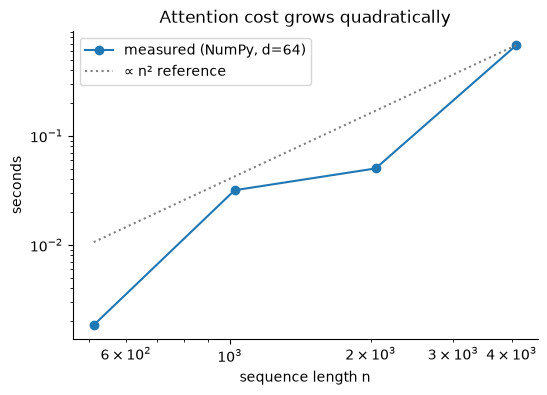

In [6]:
rng = np.random.default_rng(0)
lengths_n, times = [512, 1024, 2048, 4096], []
for n in lengths_n:
    Q = rng.normal(size=(n, 64)); K = rng.normal(size=(n, 64)); V = rng.normal(size=(n, 64))
    best = np.inf
    for _ in range(5):
        t = time.perf_counter(); au.scaled_dot_product_attention(Q, K, V); best = min(best, time.perf_counter() - t)
    times.append(best)
    print(f"n = {n:5d}: {best * 1e3:8.1f} ms | score matrix {n * n:>10,d} entries = {n * n * 8 / 1e6:6.1f} MB (float64)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(lengths_n, times, "o-", label="measured (NumPy, d=64)")
ref = times[-1] * (np.array(lengths_n) / lengths_n[-1]) ** 2
ax.loglog(lengths_n, ref, ":", color="grey", label="∝ n² reference")
ax.set_xlabel("sequence length n"); ax.set_ylabel("seconds"); ax.set_title("Attention cost grows quadratically"); ax.legend()
plt.show()

At small $n$ fixed overheads dominate the timing; at large $n$ each doubling of the length costs roughly 4× — the quadratic regime. This is why long-context models invest in tricks such as **FlashAttention** (same maths, computed in tiles that never materialise the full $n \times n$ matrix), **sparse / sliding-window attention**, **linear attention** approximations, and the **KV cache** of Notebook 10.

## 5. Cheat-sheet: the whole course on one page

| # | concept | the one thing to remember |
|---|---------|---------------------------|
| 01 | why attention | a fixed-length vector is a bottleneck; attention lets the output **look back** at every input |
| 02 | embeddings | words → vectors; similar meaning ⇒ similar direction; similarity = **dot product** |
| 03 | Q, K, V | a **soft dictionary**: match query to keys, return a weighted mix of values; $q = xW_Q$, $k = xW_K$, $v = xW_V$ |
| 04 | the formula | $\text{softmax}(QK^\top/\sqrt{d_k})\,V$; the $\sqrt{d_k}$ stops the softmax saturating |
| 05 | heatmaps | rows = queries, columns = keys, rows sum to 1; temperature controls sharpness |
| 06 | self-attention | a sentence attends to itself; stacking gives multi-hop reasoning; verify with **ablations** |
| 07 | multi-head | several heads in parallel look at different things; reshape → attend → concat → $W_O$ |
| 08 | positions | attention is order-blind; add **positional encodings** (sinusoidal, learned, RoPE) |
| 09 | the block | attention + FFN, each with **residual + LayerNorm**; residuals keep deep stacks trainable |
| 10 | causal mask | $-\infty$ above the diagonal before softmax; no peeking; enables the KV cache |
| 11 | a real model | ~100 k parameters learn to sort in seconds; the forward pass is plain NumPy |
| 12 | BERT / GPT | encoder + masked LM vs decoder + next-token; cost grows as $n^2$ |

## 6. Where to go next

- Vaswani et al. (2017), *Attention Is All You Need* — the original Transformer paper.
- Bahdanau, Cho & Bengio (2015), *Neural Machine Translation by Jointly Learning to Align and Translate* — the attention of Notebook 01.
- Devlin et al. (2019), *BERT*; Radford et al. (2019), *Language Models are Unsupervised Multitask Learners* (GPT-2).
- Jay Alammar, *The Illustrated Transformer*; Andrej Karpathy, *nanoGPT* and *Let's build GPT* — the natural next step after Notebook 11.
- For scientists: the same architecture powers **chemical language models** (SMILES/SELFIES Transformers, ChemBERTa), **protein language models** (ESM) and **structure prediction** (AlphaFold's attention-based Evoformer).

## Key takeaways

- BERT, GPT and T5 are the **same block** with different **masks** and **objectives**.
- Pretraining is **self-supervised**: masked-word or next-token prediction on raw text.
- Parameter counts follow directly from $N$, $d$ and $V$; attention itself is a minority of the weights.
- The $O(n^2)$ cost of attention is the central engineering challenge of long contexts.

### ✏️ Exercise 1

Generate 120 characters from the prompt `"the queen"` at temperatures 0.3 and 1.5. How does the text change?

<details>
<summary><b>Show solution</b></summary>

```python
for T in (0.3, 1.5):
    print(T, repr(write("the queen", n=120, temperature=T)))
```

Low temperature → safe, repetitive text; high temperature → creative but misspelled.

</details>

### ✏️ Exercise 2

Use `gpt_params` to estimate a model with 32 blocks, d=4096, vocabulary 32,000 and context 4,096 (roughly LLaMA-7B's shape — LLaMA uses a different FFN, so expect only a ballpark).

<details>
<summary><b>Show solution</b></summary>

```python
print(gpt_params(32, 4096, vocab=32000, ctx=4096) / 1e9, "billion")
```



</details>

### ✏️ Exercise 3

How much memory would one float16 attention score matrix take for a 128,000-token context, per head?

<details>
<summary><b>Show solution</b></summary>

```python
n = 128_000
print(n * n * 2 / 1e9, "GB")   # ≈ 32.8 GB per head, per layer — hence FlashAttention
```



</details>